# Analytical and Numerical Greeks

## Objective

This notebook investigates the sensitivities of European
option prices under the Black-Scholes model.

Five Greeks are considered:
- Delta: sensitivity to the underlying price.
- Gamma: second-order sensitivity to the underlying price.
- Vega: sensitivity to volatility.
- Theta: sensitivity to calendar time.
- Rho: sensitivity to the risk-free rate.

## Methodology

Analytical Greeks are calculated using closed-form
Black-Scholes expressions.

Numerical Greeks are estimated using central finite
differences and compared against analytical benchmarks.

The analysis also investigates the trade-off between
truncation error and floating-point round-off error
when selecting finite difference step sizes.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root
project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

assert (project_root / "src").is_dir(), "Project root not found"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import pricing and Greeks modules
from src.black_scholes import black_scholes
from src import greeks as gr

# Model parameters
S = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

S_values = np.linspace(50, 150, 200)


# Short aliases for the Greeks functions
analytical_delta = gr.analytical_delta
analytical_gamma = gr.analytical_gamma
analytical_vega = gr.analytical_vega
analytical_theta = gr.analytical_theta
analytical_rho = gr.analytical_rho

numerical_delta = gr.numerical_delta
numerical_gamma = gr.numerical_gamma
numerical_vega = gr.numerical_vega
numerical_theta = gr.numerical_theta
numerical_rho = gr.numerical_rho

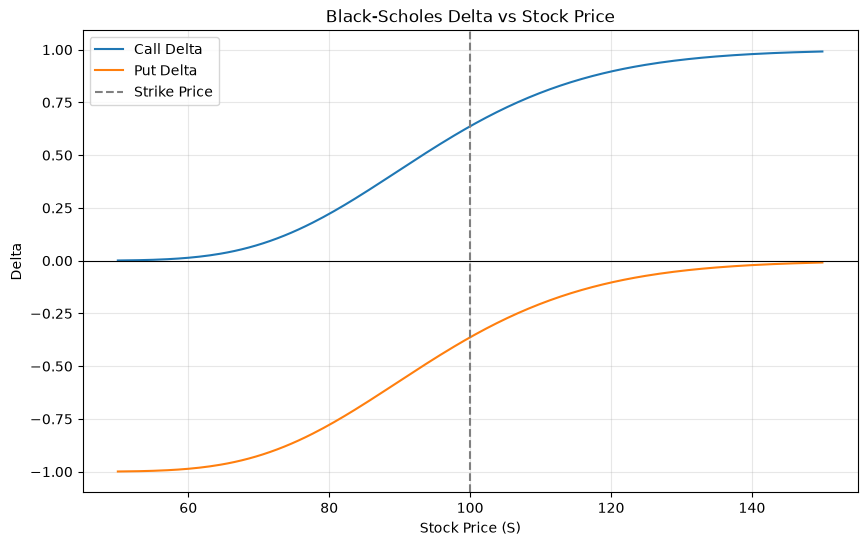

In [2]:
# Stock price range
S_values = np.linspace(50, 150, 200)

# Calculate analytical Deltas
call_deltas = analytical_delta(S_values, K, T, r, sigma, "call")
put_deltas = analytical_delta(S_values, K, T, r, sigma, "put")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(S_values, call_deltas, label="Call Delta")
plt.plot(S_values, put_deltas, label="Put Delta")

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(K, color="gray", linestyle="--", label="Strike Price")

plt.xlabel("Stock Price (S)")
plt.ylabel("Delta")
plt.title("Black-Scholes Delta vs Stock Price")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

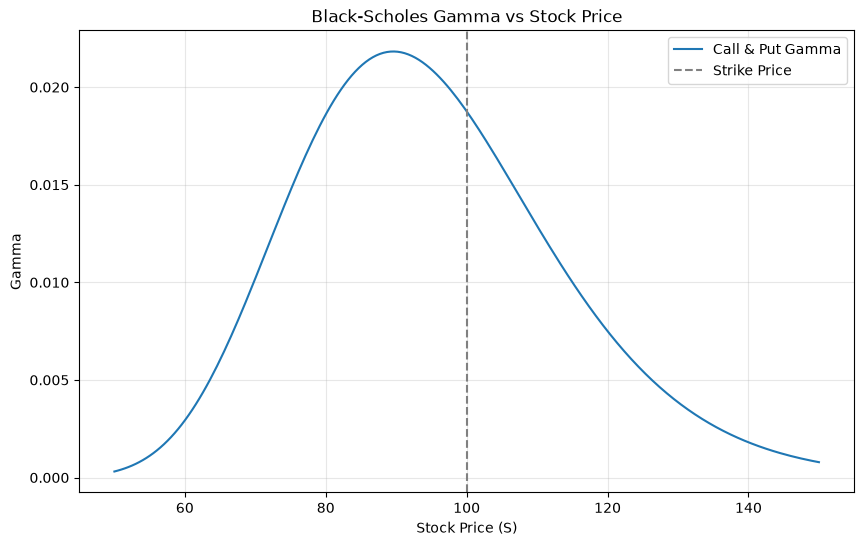

In [3]:
# Calculate Gamma across stock prices
gamma_values = analytical_gamma(S_values, K, T, r, sigma)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(S_values, gamma_values, label="Call & Put Gamma")

plt.axvline(K, color="gray", linestyle="--", label="Strike Price")

plt.xlabel("Stock Price (S)")
plt.ylabel("Gamma")
plt.title("Black-Scholes Gamma vs Stock Price")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

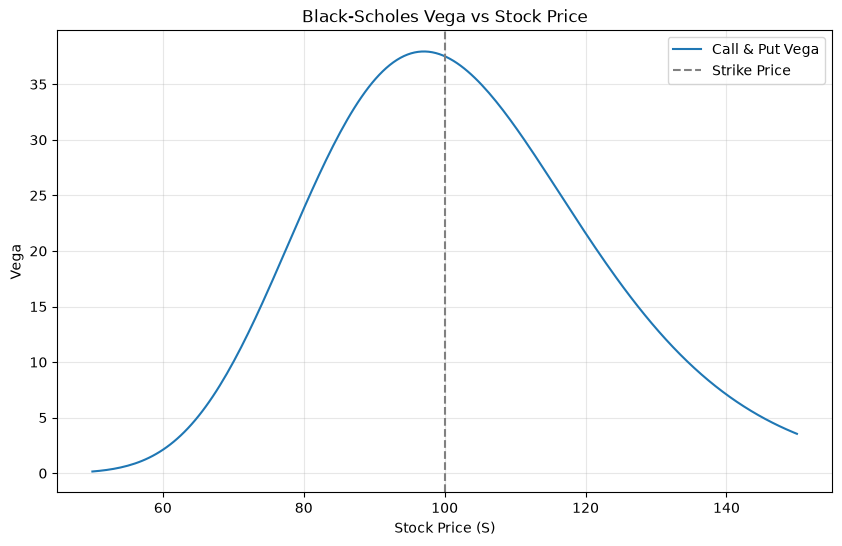

In [4]:
# Calculate Vega across stock prices
vega_values = analytical_vega(S_values, K, T, r, sigma)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(S_values, vega_values, label="Call & Put Vega")

plt.axvline(K, color="gray", linestyle="--", label="Strike Price")

plt.xlabel("Stock Price (S)")
plt.ylabel("Vega")
plt.title("Black-Scholes Vega vs Stock Price")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

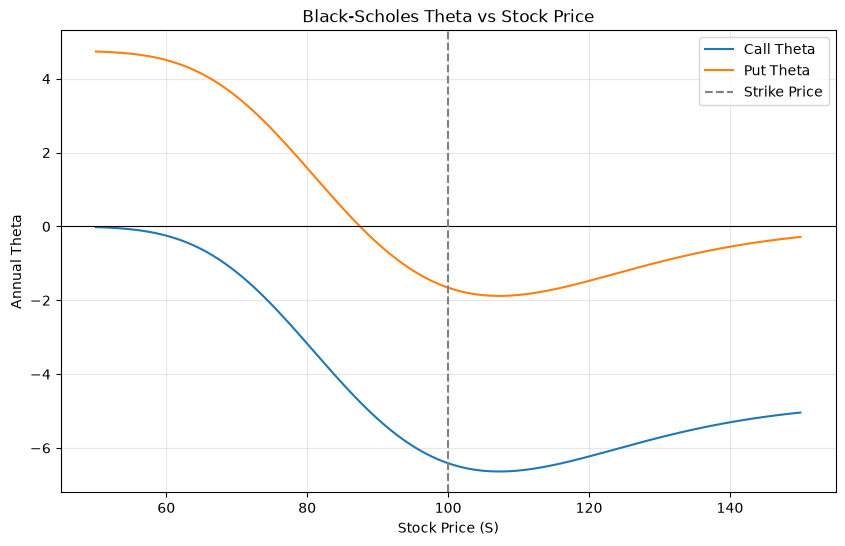

In [5]:
# Calculate Theta across stock prices
call_theta_values = analytical_theta(
    S_values, K, T, r, sigma, "call"
)

put_theta_values = analytical_theta(
    S_values, K, T, r, sigma, "put"
)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(S_values, call_theta_values, label="Call Theta")
plt.plot(S_values, put_theta_values, label="Put Theta")

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(K, color="gray", linestyle="--", label="Strike Price")

plt.xlabel("Stock Price (S)")
plt.ylabel("Annual Theta")
plt.title("Black-Scholes Theta vs Stock Price")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

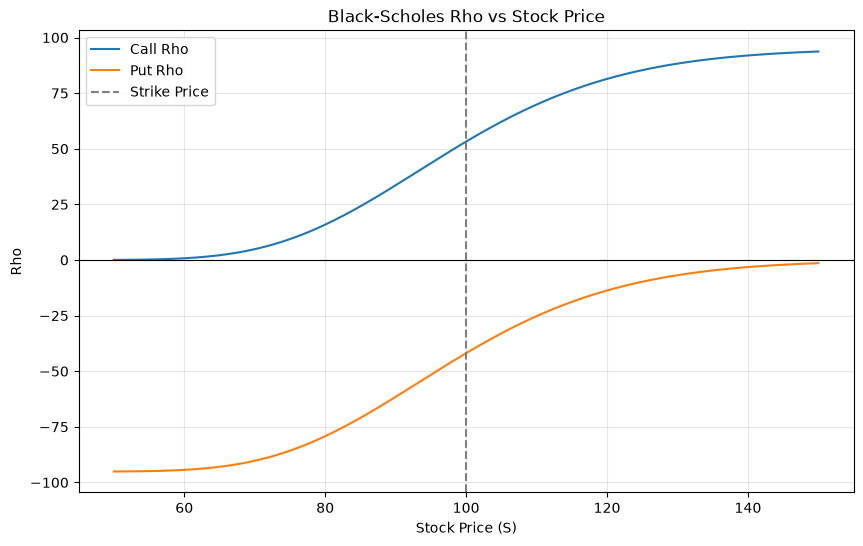

In [6]:
# Calculate Rho across stock prices
call_rho_values = analytical_rho(
    S_values, K, T, r, sigma, "call"
)

put_rho_values = analytical_rho(
    S_values, K, T, r, sigma, "put"
)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(S_values, call_rho_values, label="Call Rho")
plt.plot(S_values, put_rho_values, label="Put Rho")

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(K, color="gray", linestyle="--", label="Strike Price")

plt.xlabel("Stock Price (S)")
plt.ylabel("Rho")
plt.title("Black-Scholes Rho vs Stock Price")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Best step size: 1.29e-04
Minimum absolute error: 1.86e-12


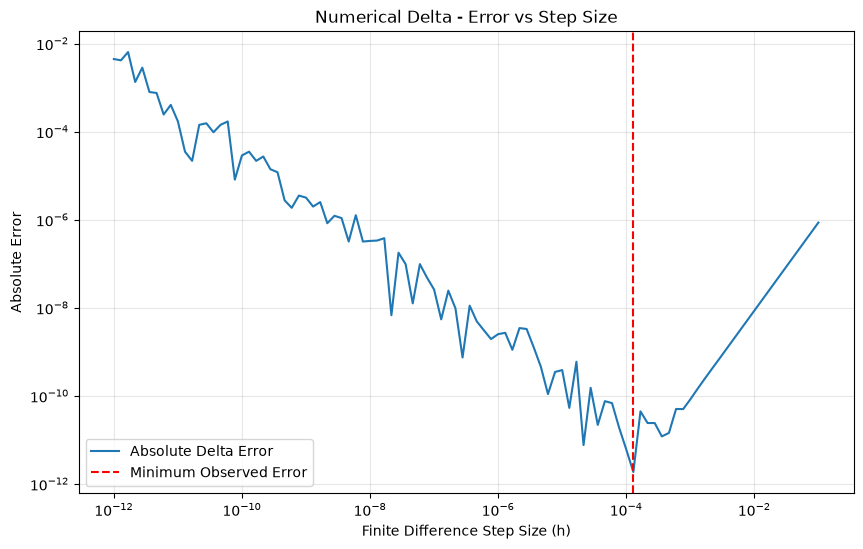

In [7]:
# Different finite difference step sizes
h_values = np.logspace(-1, -12, 100)

# Analytical Delta benchmark
delta_exact = analytical_delta(S, K, T, r, sigma, "call")

# Numerical errors
delta_errors = []

for h in h_values:

    delta_num = numerical_delta(
        S, K, T, r, sigma, "call", h=h
    )

    error = abs(delta_num - delta_exact)
    delta_errors.append(error)

delta_errors = np.array(delta_errors)

# Find smallest observed error
best_index = np.argmin(delta_errors)

print(f"Best step size: {h_values[best_index]:.2e}")
print(f"Minimum absolute error: {delta_errors[best_index]:.2e}")

# Plot
plt.figure(figsize=(10, 6))

plt.loglog(h_values, delta_errors, label="Absolute Delta Error")

plt.axvline(
    h_values[best_index],
    color="red",
    linestyle="--",
    label="Minimum Observed Error"
)

plt.xlabel("Finite Difference Step Size (h)")
plt.ylabel("Absolute Error")
plt.title("Numerical Delta - Error vs Step Size")

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

Best Gamma step size: 8.11e-03
Minimum Gamma error: 5.78e-12


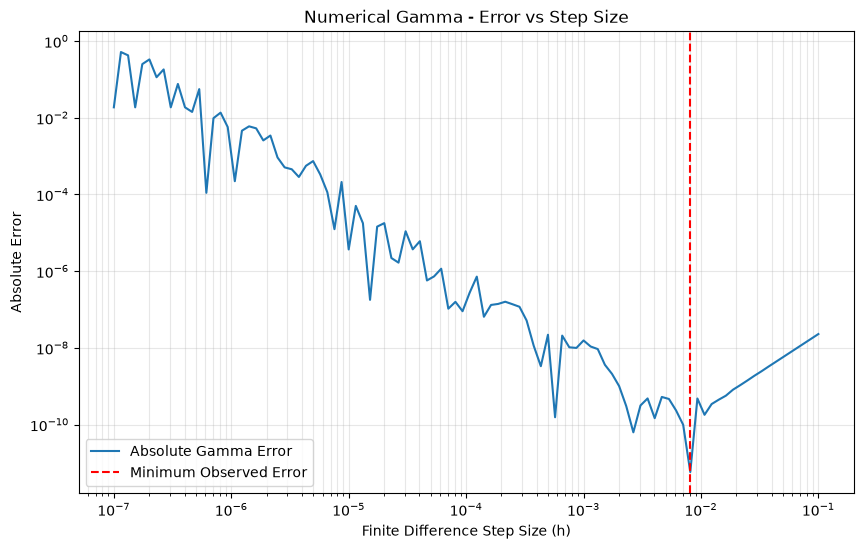

In [8]:
# Step sizes for Gamma
h_gamma = np.logspace(-1, -7, 100)

# Analytical benchmark
gamma_exact = analytical_gamma(S, K, T, r, sigma)

# Numerical errors
gamma_errors = []

for h in h_gamma:

    gamma_num = numerical_gamma(
        S, K, T, r, sigma, "call", h=h
    )

    gamma_errors.append(abs(gamma_num - gamma_exact))

gamma_errors = np.array(gamma_errors)

# Best observed step size
best_index = np.argmin(gamma_errors)

print(f"Best Gamma step size: {h_gamma[best_index]:.2e}")
print(f"Minimum Gamma error: {gamma_errors[best_index]:.2e}")

# Plot
plt.figure(figsize=(10, 6))

plt.loglog(h_gamma, gamma_errors, label="Absolute Gamma Error")

plt.axvline(
    h_gamma[best_index],
    color="red",
    linestyle="--",
    label="Minimum Observed Error"
)

plt.xlabel("Finite Difference Step Size (h)")
plt.ylabel("Absolute Error")
plt.title("Numerical Gamma - Error vs Step Size")

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [9]:
import pandas as pd

# Analytical and numerical functions
greeks = {
    "Delta": (analytical_delta, numerical_delta),
    "Gamma": (analytical_gamma, numerical_gamma),
    "Vega": (analytical_vega, numerical_vega),
    "Theta": (analytical_theta, numerical_theta),
    "Rho": (analytical_rho, numerical_rho)
}

results = []

for option_type in ["call", "put"]:

    for greek, (analytical_func, numerical_func) in greeks.items():

        if greek in ["Gamma", "Vega"]:
            analytical = analytical_func(S, K, T, r, sigma)
            numerical = numerical_func(
                S, K, T, r, sigma, option_type
            )
        else:
            analytical = analytical_func(
                S, K, T, r, sigma, option_type
            )
            numerical = numerical_func(
                S, K, T, r, sigma, option_type
            )

        abs_error = abs(analytical - numerical)

        rel_error = (
            abs_error / abs(analytical) * 100
            if analytical != 0 else np.nan
        )

        results.append({
            "Option": option_type.capitalize(),
            "Greek": greek,
            "Analytical": analytical,
            "Numerical": numerical,
            "Absolute Error": abs_error,
            "Relative Error (%)": rel_error
        })

# Create DataFrame
comparison_df = pd.DataFrame(results)

# Display formatted results
display(
    comparison_df.style.format({
        "Analytical": "{:.8f}",
        "Numerical": "{:.8f}",
        "Absolute Error": "{:.2e}",
        "Relative Error (%)": "{:.6f}"
    }))

,Option,Greek,Analytical,Numerical,Absolute Error,Relative Error (%)
0,Call,Delta,0.63683065,0.63683064,8.60e-09,0.000001
1,Call,Gamma,0.01876202,0.01876199,2.30e-08,0.000122
2,Call,Vega,37.52403469,37.52403439,3.04e-07,0.000001
3,Call,Theta,-6.41402755,-6.41402755,4.92e-09,0.000000
4,Call,Rho,53.23248155,53.23248077,7.71e-07,0.000001
5,Put,Delta,-0.36316935,-0.36316936,8.60e-09,0.000002
6,Put,Gamma,0.01876202,0.01876199,2.30e-08,0.000122
7,Put,Vega,37.52403469,37.52403439,3.04e-07,0.000001
8,Put,Theta,-1.65788042,-1.65788043,4.92e-09,0.000000
9,Put,Rho,-41.89046090,-41.89046183,9.30e-07,0.000002


In [10]:
import importlib
import src.greeks as gr

importlib.reload(gr)

# Analytical Greeks
print("Analytical Greeks:")
print(f"Delta: {gr.analytical_delta(S, K, T, r, sigma):.6f}")
print(f"Gamma: {gr.analytical_gamma(S, K, T, r, sigma):.6f}")
print(f"Vega:  {gr.analytical_vega(S, K, T, r, sigma):.6f}")
print(f"Theta: {gr.analytical_theta(S, K, T, r, sigma):.6f}")
print(f"Rho:   {gr.analytical_rho(S, K, T, r, sigma):.6f}")

print("\nNumerical Greeks:")
print(f"Delta: {gr.numerical_delta(S, K, T, r, sigma):.6f}")
print(f"Gamma: {gr.numerical_gamma(S, K, T, r, sigma):.6f}")
print(f"Vega:  {gr.numerical_vega(S, K, T, r, sigma):.6f}")
print(f"Theta: {gr.numerical_theta(S, K, T, r, sigma):.6f}")
print(f"Rho:   {gr.numerical_rho(S, K, T, r, sigma):.6f}")

Analytical Greeks:
Delta: 0.636831
Gamma: 0.018762
Vega:  37.524035
Theta: -6.414028
Rho:   53.232482

Numerical Greeks:
Delta: 0.636831
Gamma: 0.018762
Vega:  37.524034
Theta: -6.414028
Rho:   53.232481
